Coefficient or Slope:  [17.2982057]
Intercept:  156.47058823529412
114.84069295228699
9.66512588679501
10.716374991212605
Score: 0.7360826717981276
Adjusted Score: 0.6701033397476595


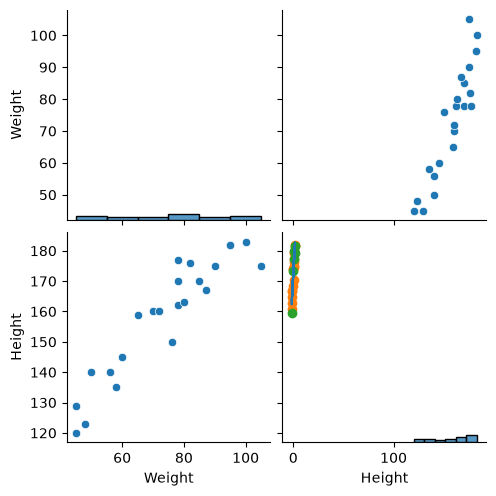

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

#  Reading the data
df = pd.read_csv(r"C:/Users/shari/Downloads/DataScience Bootcamp/Python/FeatureEngineering/height-weight.csv")
df.head()

df.corr()
sns.pairplot(df)

# checking null values if any

df.isnull().sum()

# dependent and independent features

X = df[['Weight']]
y = df['Height']

# Train Test Split
from sklearn.model_selection import train_test_split

#initialization
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25,random_state=42)

# Standardization
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# standardizing Training data
X_train = scaler.fit_transform(X_train)


#standardizinf Test data
X_test = scaler.transform(X_test)

# Applying Linear Regression on training data

from sklearn.linear_model import LinearRegression

#initialize
regression = LinearRegression(n_jobs=-1)
regression.fit(X_train, y_train)

print("Coefficient or Slope: ",regression.coef_)
print("Intercept: ", regression.intercept_)

# plot the best fit line on training data

plt.scatter(X_train, y_train)

plt.plot(X_train, regression.predict(X_train))


# Predict the output
plt.scatter(X_test, y_test)
y_pred = regression.predict(X_test)

# Performance metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error,root_mean_squared_error
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
print(mse)
print(mae)
print(rmse)

# perfromance mertics
from sklearn.metrics import r2_score
score = r2_score(y_test, y_pred)
print("Score:",score)

adjusted_score = 1-((1-r2_score(y_test, y_pred))*(len(y_test) - 1)/(len(y_test) - X_test.shape[1] - 1))
print("Adjusted Score:",adjusted_score)

# # OLS implementation - Ordinary Least Square

# import statsmodels.api as sm
# model = sm.OLS(y_train, X_train).fit()

# prediction = model.predict(X_test)

# print(model.summary())

# # prediction for new data
# regression.predict([[72]])

# regression.predict([[72]])

# regression.predict(scaler.transform([[72]]))

In [7]:
# Weight = 80

scaled_wt = scaler.transform([[80]])
scaled_wt

c:\Users\shari\Downloads\DataScience Bootcamp\Python\FeatureEngineering\Fenv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([[0.45613165]])

In [10]:
regression.predict(scaled_wt)

array([164.36084726])